# 흡연 여부에 따른 건강 지표 차이 분석

- **기간:** 2026.01 · 팀 프로젝트 4명 (이 노트북은 개인 분석 파트)
- **담당:** 결측치 처리·전처리, 파생 변수 설계, 가설 검정
- **데이터:** 건강검진 데이터 7,000건 × 18개 항목 (흡연 여부 `label` 포함)
  - 데이터 파일은 재배포 제한으로 저장소에 포함하지 않았습니다.

### 분석 목표
흡연자와 비흡연자 사이에 건강 지표 차이가 있는지 통계적으로 검증합니다.

## 0. 가설 수립

| | 지표 | 귀무가설 (H₀) | 대립가설 (H₁) | 검정 방법 |
|---|---|---|---|---|
| 가설 1 | 중성 지방 | 흡연자와 비흡연자의 중성 지방 평균은 같다 | 두 집단의 평균은 다르다 | t-검정, OLS 회귀 |
| 가설 2 | 충치 | 흡연자와 비흡연자의 충치 발생 빈도는 같다 | 두 집단의 충치 발생 빈도는 다르다 | 카이제곱 검정, OLS 회귀 |
| 가설 3 | 저밀도지단백(LDL) | 흡연 여부·나이대별 LDL 평균은 같다 | 흡연 여부·나이대에 따라 LDL 평균이 다르다 | 이원 분산분석 |

- 유의수준: 5%

## 1. 환경 설정

In [1]:
# Colab 한글 폰트 설치
# 처음 한 번 실행한 뒤 '런타임 > 세션 다시 시작'을 하고, 다시 위에서부터 실행합니다.
!apt-get -qq install -y fonts-nanum > /dev/null
!fc-cache -f > /dev/null
!rm -rf ~/.cache/matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

plt.rc('font', family='NanumBarunGothic')     # 그래프 한글 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False    # 마이너스 기호 깨짐 방지

ORDER = ['비흡연', '흡연']   # 흡연 여부 그래프의 막대 순서

## 2. 데이터 불러오기

In [3]:
health_data = pd.read_csv('smoking_health_data.csv')

print(f"행 개수: {health_data.shape[0]}개, 열 개수: {health_data.shape[1]}개")
health_data.head()

행 개수: 7000개, 열 개수: 18개


,ID,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,label
0,TRAIN_0000,35,170,70,24.22,1.10,1,98.0,40.0,80.0,1.3,211,75,120,15.9,1,1.53,1
1,TRAIN_0001,40,150,55,24.44,1.00,0,173.0,39.0,104.0,0.6,251,46,184,11.8,1,1.45,0
2,TRAIN_0002,60,170,50,17.30,0.75,0,96.0,40.0,61.0,0.8,144,43,89,15.3,1,1.04,0
3,TRAIN_0003,40,150,45,20.00,0.50,0,92.0,40.0,46.0,0.7,178,66,110,13.4,1,1.18,0
4,TRAIN_0004,55,155,65,27.06,NaN,0,87.0,42.0,95.0,0.9,232,62,151,13.8,1,1.32,0


## 3. 전처리

### 3-1. 구간 변수 생성
결측치를 나이대별로 처리하기 위해 BMI 구간과 나이대를 먼저 만듭니다.

In [4]:
def health_status(bmi):
    if bmi <= 18.5:
        return '저체중'
    elif bmi < 25:
        return '정상'
    elif bmi < 30:
        return '과체중'
    else:
        return '비만'

health_data['체중상태'] = health_data['BMI'].apply(health_status)


# 30~50대, 50~70대처럼 경계가 겹치지 않도록 구간을 나눔
def age_order(age):
    if age <= 30:
        return '30대 이하'
    elif age <= 50:
        return '30 ~ 40대'
    elif age <= 70:
        return '50 ~ 60대'
    else:
        return '70대 이상'

health_data['나이대'] = health_data['나이'].apply(age_order)

health_data[['BMI', '체중상태', '나이', '나이대']].head()

,BMI,체중상태,나이,나이대
0,24.22,정상,35,30 ~ 40대
1,24.44,정상,40,30 ~ 40대
2,17.30,저체중,60,50 ~ 60대
3,20.00,정상,40,30 ~ 40대
4,27.06,과체중,55,50 ~ 60대


### 3-2. 결측치 처리

In [5]:
missing_count = health_data.isnull().sum()
print(missing_count[missing_count > 0])
print(f"\n전체 결측치: {missing_count.sum()}개")

시력       140
공복 혈당    140
혈압       140
중성 지방    140
dtype: int64

전체 결측치: 560개


시력·공복 혈당·혈압·중성 지방에 각각 140개(2%)의 결측치가 있습니다. 변수 특성에 맞게 처리했습니다.

- **시력:** 0.1 단위의 이산값이 많아 최빈값으로 대체
- **혈압:** 이상치 영향을 줄이기 위해 중앙값으로 대체
- **공복 혈당:** 평균값으로 대체
- **중성 지방:** 나이대마다 분포가 달라, 전체 평균 대신 나이대별 평균으로 대체

In [6]:
# 시력: 최빈값
eye_mode = health_data['시력'].mode()[0]
health_data['시력'] = health_data['시력'].fillna(eye_mode)

# 혈압: 중앙값
bp_median = health_data['혈압'].median()
health_data['혈압'] = health_data['혈압'].fillna(bp_median)

# 공복 혈당: 평균값
bs_mean = health_data['공복 혈당'].mean()
health_data['공복 혈당'] = health_data['공복 혈당'].fillna(bs_mean)

# 중성 지방: 나이대별 평균값
fat_by_age_mean = health_data.groupby('나이대')['중성 지방'].mean().round(1)
health_data['중성 지방'] = health_data['중성 지방'].fillna(health_data['나이대'].map(fat_by_age_mean))

print(f"시력 → 최빈값 {eye_mode}")
print(f"혈압 → 중앙값 {bp_median}")
print(f"공복 혈당 → 평균값 {bs_mean:.1f}")
print(f"중성 지방 → 나이대별 평균값 {fat_by_age_mean.to_dict()}")
print(f"\n처리 후 결측치: {health_data.isnull().sum().sum()}개")

시력 → 최빈값 1.2
혈압 → 중앙값 45.0
공복 혈당 → 평균값 99.3
중성 지방 → 나이대별 평균값 {'30 ~ 40대': 128.8, '30대 이하': 120.8, '50 ~ 60대': 128.2, '70대 이상': 111.0}

처리 후 결측치: 0개


### 3-3. 파생 변수 생성
임상 기준에 맞춰 위험군과 상태 변수를 만듭니다.

In [7]:
# 저밀도지단백 위험군 (130 mg/dL 이상)
health_data['저밀도지단백 수치'] = np.where(health_data['저밀도지단백'] >= 130, '위험', '정상')

# 시력 상태
health_data['시력 상태'] = np.where(health_data['시력'] >= 1.0, '정상', '시력 저하')

# 중성 지방 상태 (150 미만 정상, 150~199 경계, 200 이상 위험)
health_data['중성지방 상태'] = pd.cut(health_data['중성 지방'],
                                  bins=[0, 150, 200, np.inf],
                                  labels=['정상', '경계', '위험'], right=False)

# 빈혈 여부 (헤모글로빈 12 g/dL 미만)
health_data['빈혈 여부'] = np.where(health_data['헤모글로빈'] < 12, '빈혈', '정상')

# 라벨 변수
health_data['흡연상태'] = health_data['label'].map({0: '비흡연', 1: '흡연'})
health_data['충치상태'] = health_data['충치'].map({0: '충치없음', 1: '충치있음'})

health_data[['저밀도지단백 수치', '시력 상태', '중성지방 상태', '빈혈 여부', '흡연상태', '충치상태']].head()

,저밀도지단백 수치,시력 상태,중성지방 상태,빈혈 여부,흡연상태,충치상태
0,정상,정상,정상,정상,흡연,충치있음
1,위험,정상,정상,빈혈,비흡연,충치없음
2,정상,시력 저하,정상,정상,비흡연,충치없음
3,정상,시력 저하,정상,정상,비흡연,충치없음
4,위험,정상,정상,정상,비흡연,충치없음


## 4. 단변량 분석

In [8]:
health_data.describe()

,나이,키(cm),몸무게(kg),BMI,시력,충치,공복 혈당,혈압,중성 지방,혈청 크레아티닌,콜레스테롤,고밀도지단백,저밀도지단백,헤모글로빈,요 단백,간 효소율,label
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,43.973571,164.781429,65.932857,24.144423,1.015186,0.227429,99.307289,45.544000,127.027343,0.884900,197.276571,57.355429,115.346857,14.631914,1.083857,1.144696,0.367286
std,12.063793,9.170213,12.978702,3.501945,0.426631,0.419202,20.977056,8.743135,72.484925,0.241523,36.306494,14.506945,41.788153,1.540907,0.392051,0.432735,0.482100
min,20.000000,135.000000,30.000000,14.270000,0.100000,0.000000,57.000000,14.000000,21.000000,0.100000,86.000000,18.000000,1.000000,4.900000,1.000000,0.140000,0.000000
25%,35.000000,160.000000,55.000000,21.600000,0.800000,0.000000,89.000000,40.000000,74.000000,0.800000,173.000000,47.000000,92.000000,13.600000,1.000000,0.840000,0.000000
50%,40.000000,165.000000,65.000000,23.880000,1.000000,0.000000,96.000000,45.000000,108.000000,0.900000,195.000000,55.000000,113.000000,14.800000,1.000000,1.100000,0.000000
75%,50.000000,170.000000,75.000000,26.120000,1.200000,0.000000,103.000000,50.000000,160.000000,1.000000,219.000000,66.000000,136.000000,15.700000,1.000000,1.380000,1.000000
max,85.000000,190.000000,130.000000,42.450000,9.900000,1.000000,386.000000,91.000000,399.000000,10.000000,395.000000,157.000000,1340.000000,20.900000,5.000000,5.670000,1.000000


In [9]:
print(health_data['흡연상태'].value_counts(), '\n')
print(health_data['충치상태'].value_counts())

흡연상태
비흡연    4429
흡연     2571
Name: count, dtype: int64 

충치상태
충치없음    5408
충치있음    1592
Name: count, dtype: int64


### 4-1. 흡연 여부별 인원

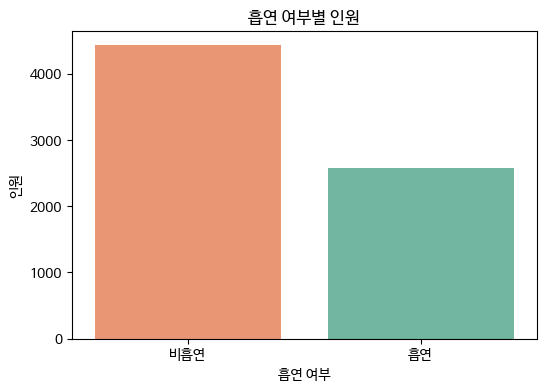

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=health_data, x='흡연상태', order=ORDER, hue='흡연상태',
              palette='Set2', legend=False)
plt.title('흡연 여부별 인원')
plt.xlabel('흡연 여부')
plt.ylabel('인원')
plt.show()

### 4-2. 흡연 여부별 BMI·헤모글로빈 분포

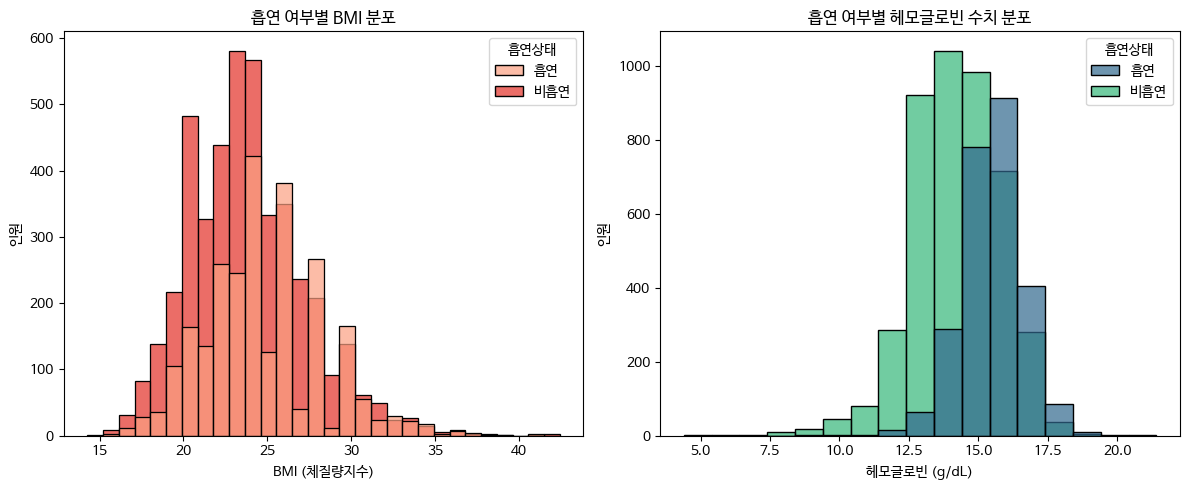

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=health_data, x='BMI', hue='흡연상태',
             palette='Reds', bins=30, alpha=0.7, ax=axes[0])
axes[0].set_title('흡연 여부별 BMI 분포')
axes[0].set_xlabel('BMI (체질량지수)')
axes[0].set_ylabel('인원')

sns.histplot(data=health_data, x='헤모글로빈', hue='흡연상태',
             palette='viridis', bins=30, alpha=0.7, discrete=True, ax=axes[1])
axes[1].set_title('흡연 여부별 헤모글로빈 수치 분포')
axes[1].set_xlabel('헤모글로빈 (g/dL)')
axes[1].set_ylabel('인원')

plt.tight_layout()
plt.show()

### 4-3. 중성 지방과 체중 상태

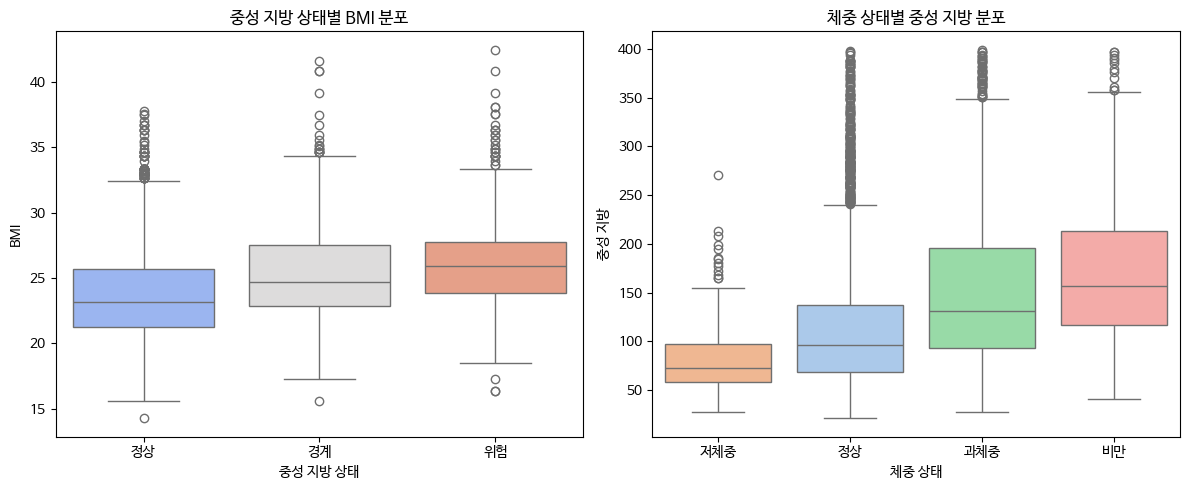

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=health_data, x='중성지방 상태', y='BMI', hue='중성지방 상태',
            palette='coolwarm', legend=False, ax=axes[0])
axes[0].set_title('중성 지방 상태별 BMI 분포')
axes[0].set_xlabel('중성 지방 상태')

sns.boxplot(data=health_data, x='체중상태', y='중성 지방', hue='체중상태',
            order=['저체중', '정상', '과체중', '비만'], palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('체중 상태별 중성 지방 분포')
axes[1].set_xlabel('체중 상태')

plt.tight_layout()
plt.show()

### 4-4. 수치형 변수 간 산점도
저밀도지단백에 400 이상의 극단값(최대 1340)이 있어, 제거 전후를 함께 비교합니다.

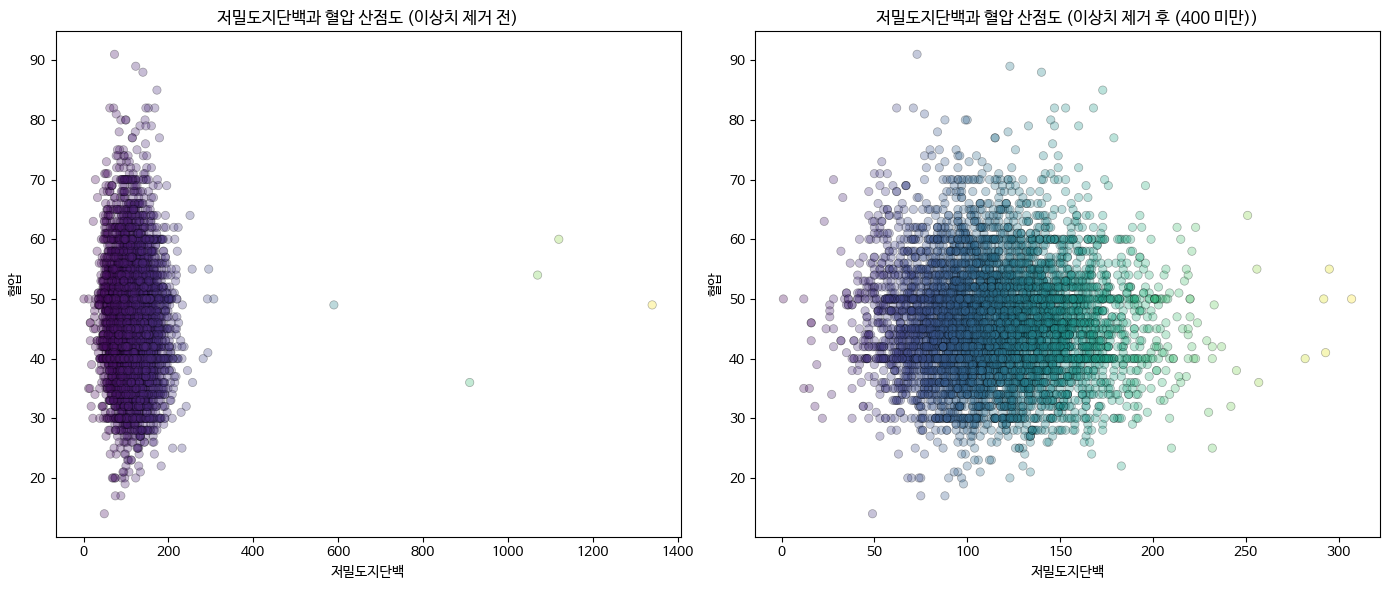

In [13]:
filtered_data = health_data[health_data['저밀도지단백'] < 400]   # 이상치 제외

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, title in zip(axes, [health_data, filtered_data], ['이상치 제거 전', '이상치 제거 후 (400 미만)']):
    ax.scatter(data['저밀도지단백'], data['혈압'], c=data['저밀도지단백'],
               linewidths=0.5, edgecolors='k', alpha=0.3)
    ax.set_title(f'저밀도지단백과 혈압 산점도 ({title})')
    ax.set_xlabel('저밀도지단백')
    ax.set_ylabel('혈압')

plt.tight_layout()
plt.show()

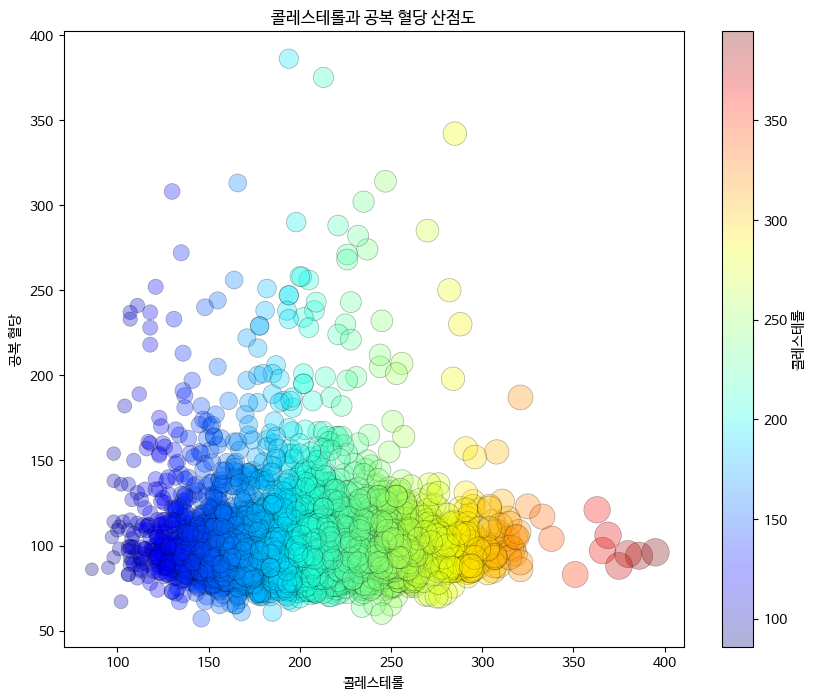

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(health_data['콜레스테롤'], health_data['공복 혈당'],
                s=health_data['콜레스테롤'], c=health_data['콜레스테롤'], cmap='jet',
                linewidths=0.5, edgecolors='k', alpha=0.3)
ax.set_title('콜레스테롤과 공복 혈당 산점도')
ax.set_xlabel('콜레스테롤')
ax.set_ylabel('공복 혈당')
fig.colorbar(sc, label='콜레스테롤')
plt.show()

### 4-5. 시력 상태·빈혈 여부 비율

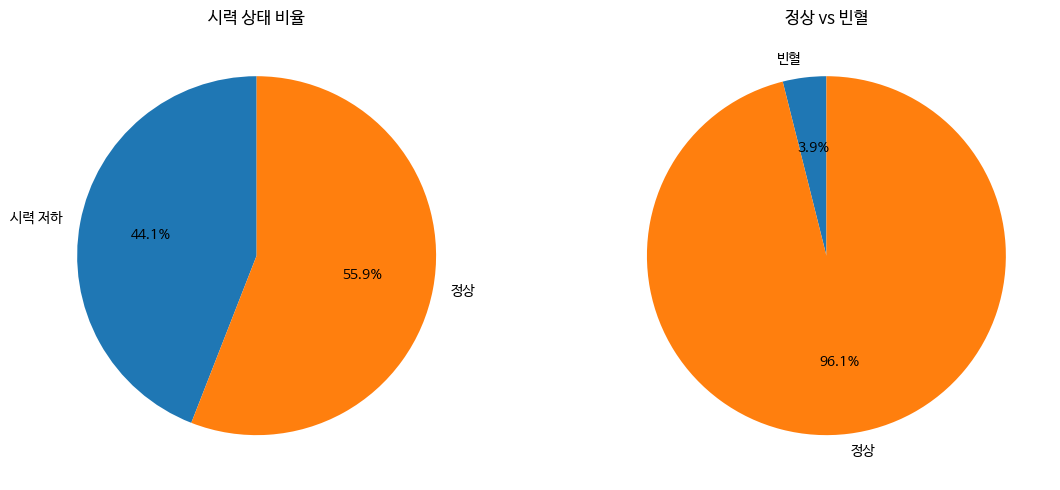

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in zip(axes, ['시력 상태', '빈혈 여부'], ['시력 상태 비율', '정상 vs 빈혈']):
    counts = health_data[col].value_counts(ascending=True)
    ax.pie(counts, labels=counts.index, startangle=90, autopct='%.1f%%')
    ax.set_title(title)
plt.tight_layout()
plt.show()

### 4-6. 의료 변수 간 상관관계

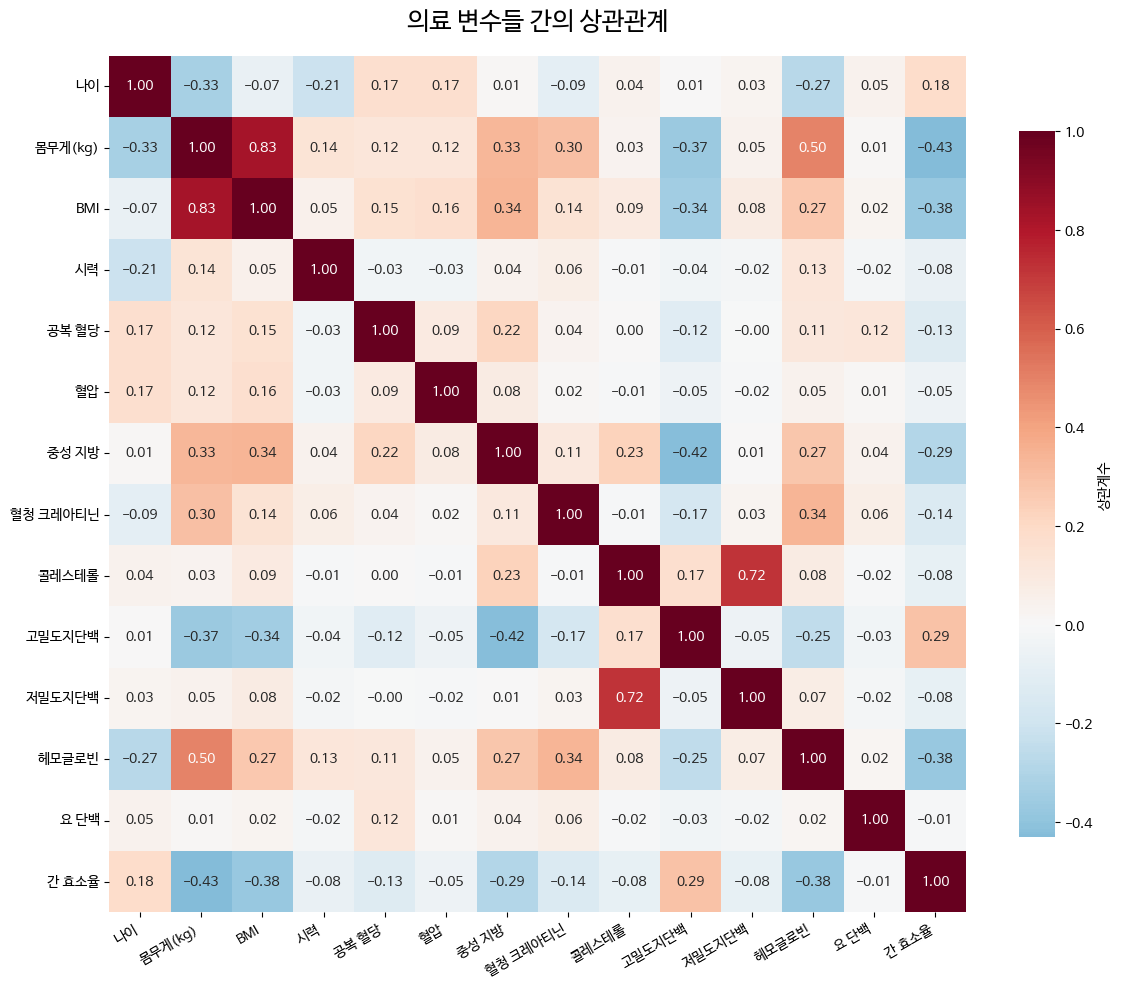

In [16]:
medical_vars = ['나이', '몸무게(kg)', 'BMI', '시력', '공복 혈당', '혈압', '중성 지방',
                '혈청 크레아티닌', '콜레스테롤', '고밀도지단백', '저밀도지단백', '헤모글로빈', '요 단백', '간 효소율']
correlation_matrix = health_data[medical_vars].corr()   # 피어슨 상관계수

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            cbar_kws={'label': '상관계수', 'shrink': 0.8})
plt.title('의료 변수들 간의 상관관계', fontsize=18, pad=20)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

### 4-7. 흡연 여부별 변수 쌍 관계 (pairplot)

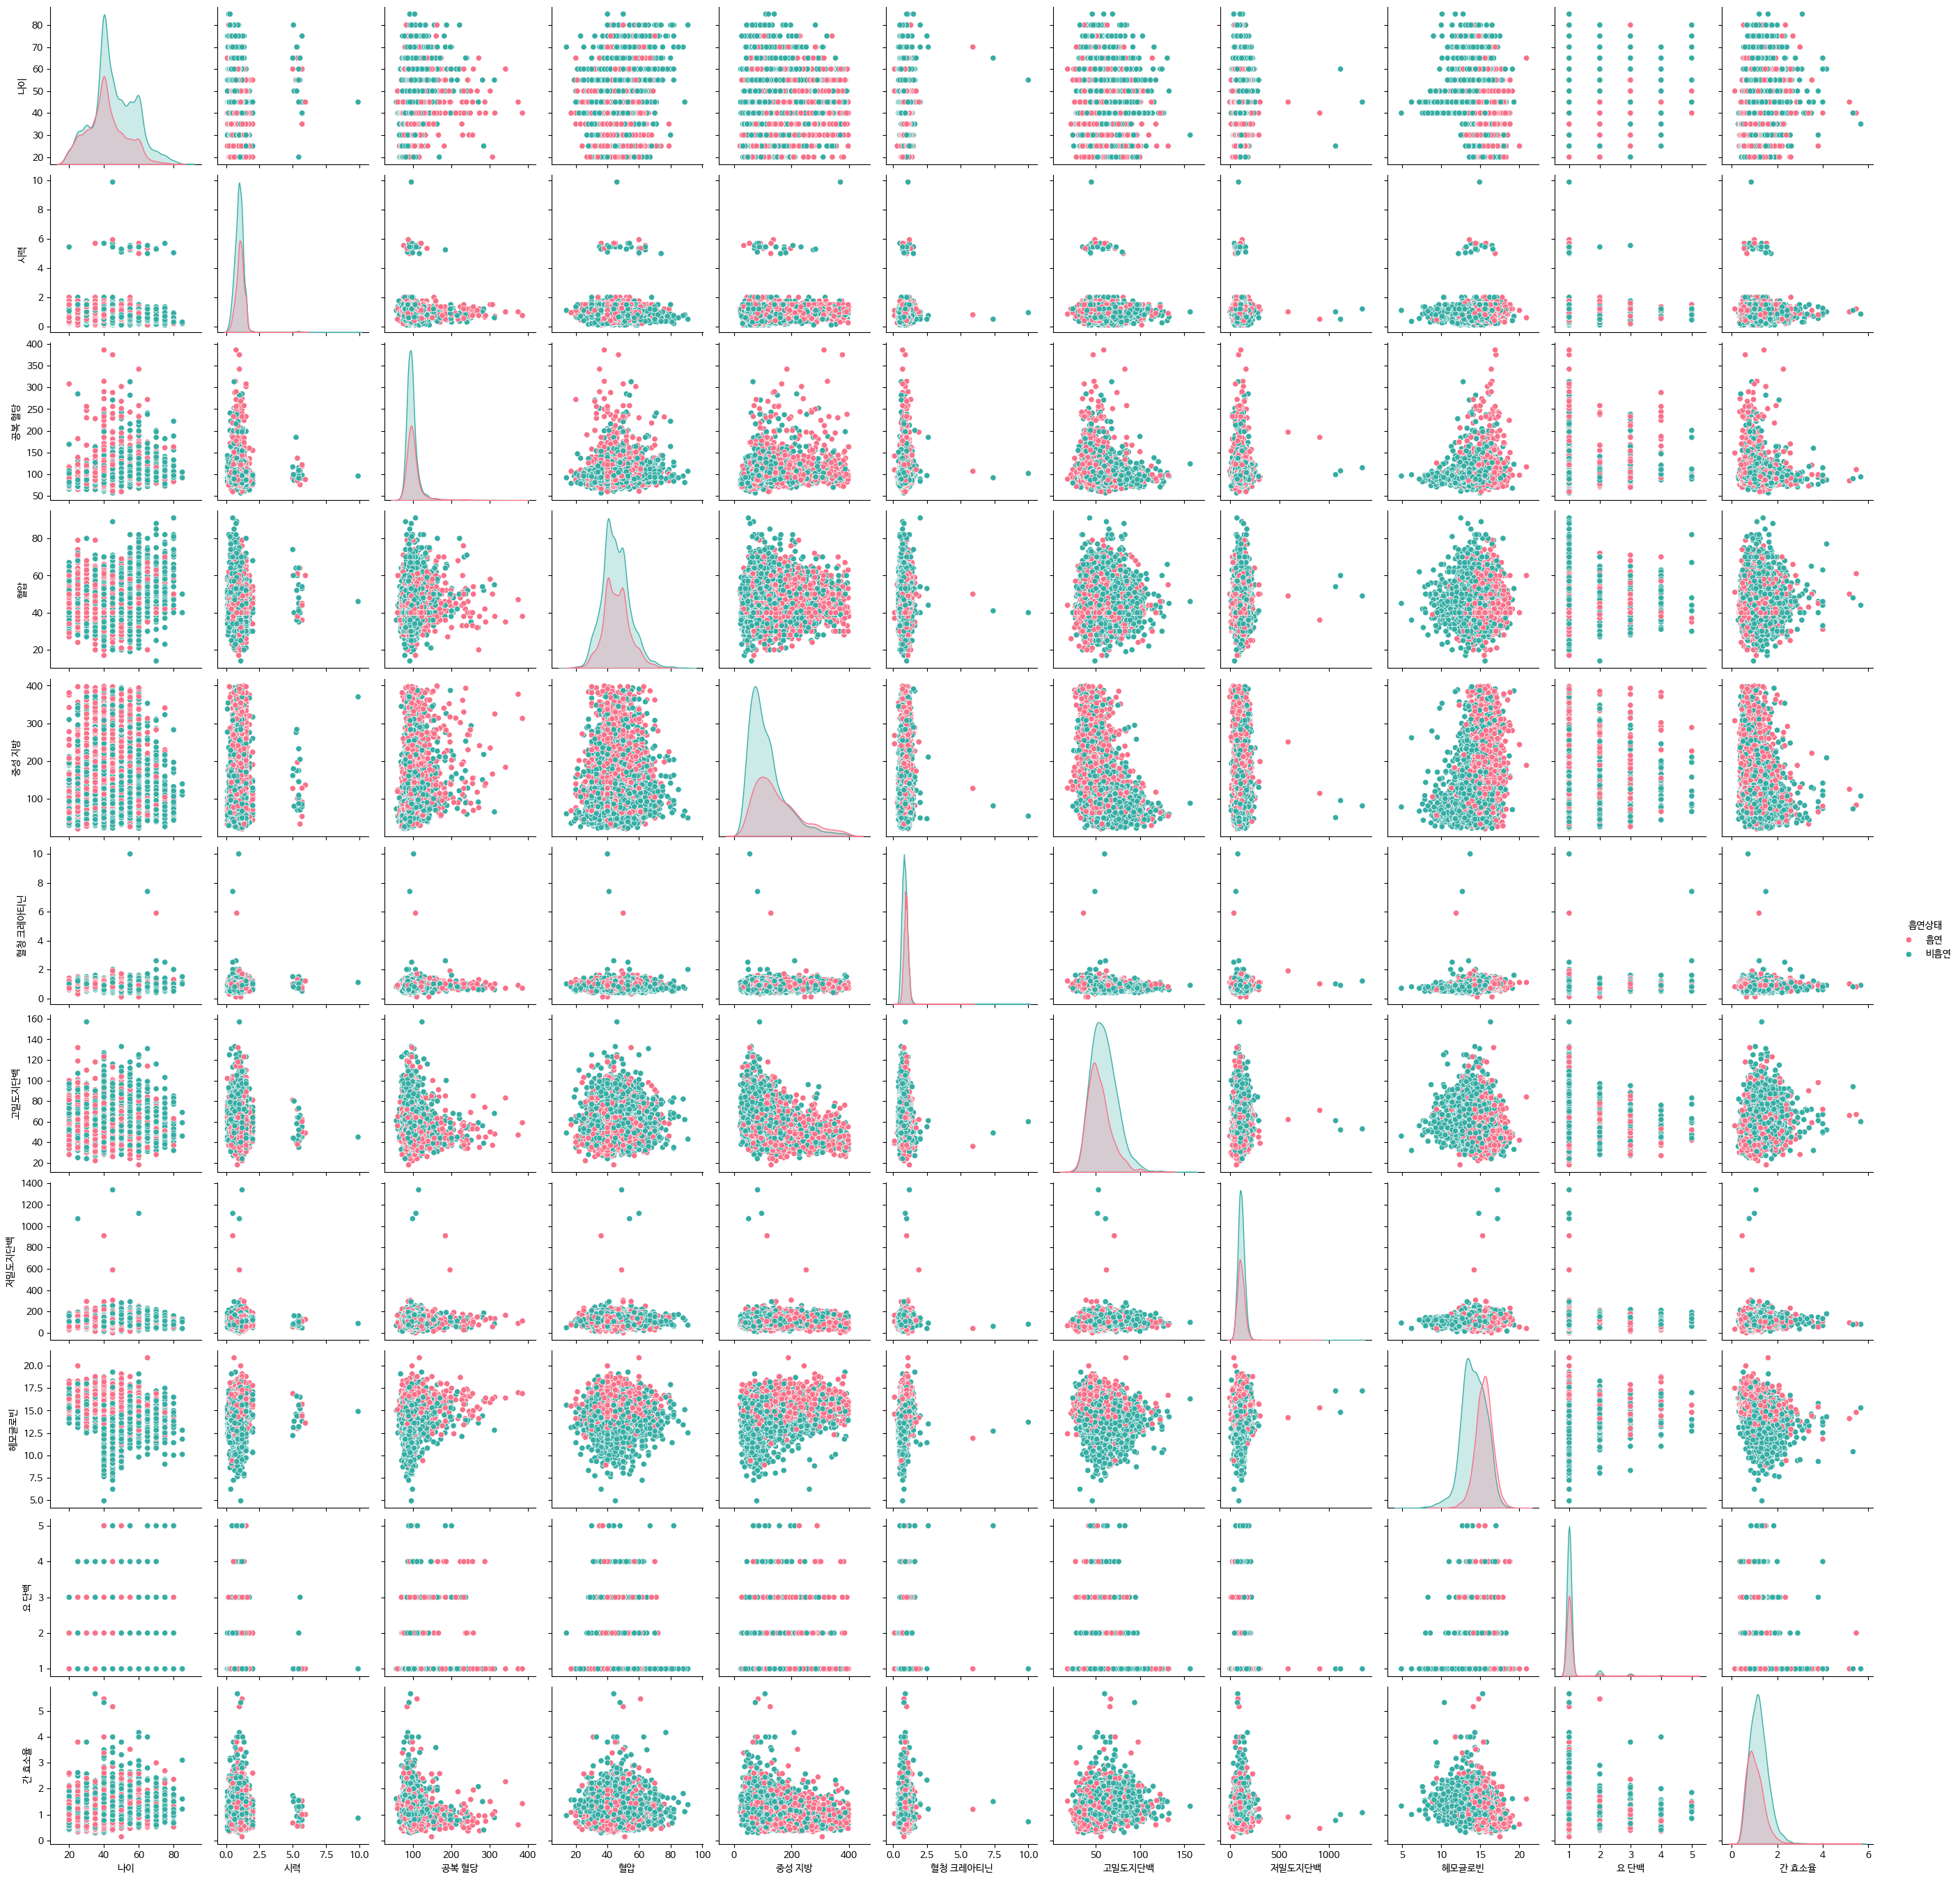

In [20]:
hdf = health_data[
    ['나이', '시력', '공복 혈당', '혈압', '중성 지방', '흡연상태',
     '혈청 크레아티닌', '고밀도지단백', '저밀도지단백', '헤모글로빈', '요 단백', '간 효소율']
]

sns.pairplot(hdf, hue='흡연상태', palette='husl')
plt.show()

## 5. 가설 검정

### 가설 1. 흡연 여부 → 중성 지방
범주(흡연 여부) → 숫자(중성 지방)이므로 독립표본 t-검정을 하고, OLS 회귀로 차이의 크기를 확인합니다.

In [17]:
smokers = health_data.loc[health_data['흡연상태'] == '흡연', '중성 지방']
non_smokers = health_data.loc[health_data['흡연상태'] == '비흡연', '중성 지방']

t_stat, p_val1 = stats.ttest_ind(smokers, non_smokers, nan_policy='omit')
print(f"t-검정 p-value: {p_val1:.3e}\n")

model1 = ols('Q("중성 지방") ~ C(흡연상태)', data=health_data).fit()
print(model1.summary().tables[1])

t-검정 p-value: 1.903e-96

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       113.4809      1.056    107.467      0.000     111.411     115.551
C(흡연상태)[T.흡연]    36.8825      1.742     21.168      0.000      33.467      40.298


**결과:** p < 0.001로 귀무가설을 기각합니다.
- 비흡연자의 평균 중성 지방은 약 113.5 mg/dL(Intercept)입니다.
- 흡연자는 이보다 평균 **36.88 mg/dL 더 높습니다.**

### 가설 2. 흡연 여부 → 충치
범주(흡연 여부) → 범주(충치 여부)이므로 카이제곱 검정을 하고, OLS(선형 확률 모형)로 발생률 차이를 확인합니다.

In [18]:
cross_tab = pd.crosstab(health_data['흡연상태'], health_data['충치상태'])
print('관측도수 교차표')
display(cross_tab)

chi2, p_val2, dof, expected = stats.chi2_contingency(cross_tab)
print(f"\n카이제곱 검정 p-value: {p_val2:.3e}\n")

model2 = ols('Q("충치") ~ C(흡연상태)', data=health_data).fit()
print(model2.summary().tables[1])

관측도수 교차표


충치상태,충치없음,충치있음
흡연상태,,
비흡연,3561,868
흡연,1847,724



카이제곱 검정 p-value: 2.233e-16

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.1960      0.006     31.263      0.000       0.184       0.208
C(흡연상태)[T.흡연]     0.0856      0.010      8.278      0.000       0.065       0.106


**결과:** p < 0.001로 귀무가설을 기각합니다.
- 비흡연자의 충치 발생률은 약 19.6%입니다.
- 흡연자는 약 28.2%로 **8.5%p 더 높습니다.**

### 가설 3. 흡연 여부 × 나이대 → 저밀도지단백(LDL)
독립변수가 범주 2개(흡연 여부, 나이대)이고 종속변수가 숫자이므로 이원 분산분석을 합니다.

In [19]:
model3 = ols('저밀도지단백 ~ C(흡연상태) * C(나이대)', data=health_data).fit()
anova_table = sm.stats.anova_lm(model3, typ=2)
anova_table

,sum_sq,df,F,PR(>F)
C(흡연상태),1.058595e+04,1.0,6.119893,1.339046e-02
C(나이대),7.744825e+04,3.0,14.924654,1.106522e-09
C(흡연상태):C(나이대),3.697282e+04,3.0,7.124842,8.932668e-05
Residual,1.209449e+07,6992.0,NaN,NaN


**결과:** 세 효과 모두 유의수준 5%에서 유의합니다.
- **흡연 여부 주효과 (p ≈ 0.013):** 나이대와 관계없이 흡연 여부에 따라 LDL 평균이 다릅니다.
- **나이대 주효과 (p < 0.001):** 흡연 여부와 관계없이 나이대에 따라 LDL 평균이 다릅니다.
- **상호작용 효과 (p < 0.001):** 흡연이 LDL에 미치는 영향의 크기가 나이대마다 다릅니다.

## 6. 결론

- 흡연자는 비흡연자보다 **중성 지방이 평균 36.88 mg/dL 높고**, **충치 발생률이 8.5%p 높았습니다.** 흡연이 대사 지표와 구강 건강 모두와 관련이 있음을 확인했습니다.
- LDL은 흡연 여부와 나이대가 함께 영향을 주며, 흡연의 영향이 나이대에 따라 달랐습니다.

### 한계와 개선 방향
- 흡연 여부 하나로 비교해 성별·연령 같은 교란 변수를 통제하지 못했습니다. → 다변량 회귀로 교란 변수를 함께 넣어 검증
- 나이대별 평균도 하나의 값으로 채우는 방식이라 분산이 줄어듭니다. → 결측 제거·그룹 평균·회귀 대체로 각각 검정해 결론이 유지되는지 확인